# Measuring cell hotspots

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os
import json

load in domains

In [2]:
directory = r"D:\Muspan_temp\domains" #r"E:\Amy_muspan\muspanvenv\hpc_test_outputs\single_domain"

saved_domains = os.listdir(directory)

domains = []

for s_domain in saved_domains[:4]:
    domain = ms.io.load_domain(os.path.join(directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_B24-581 AB005 COMB Rx2 R2_Scan1_Stitched.csv
Number of objects: 687301
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'Neighbourhood_ID_KNN_8'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_RADIO TN06 CAF 17460-21-A1 Rx s6_Scan1_Stitched.csv
Number of objects: 654848
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'Neighbourhood_ID_KNN_8'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_BCPP CAF B22-932 5161-09-1 Rxm s6_Scan2_Stitched.csv
Number of objects: 113453
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'Neighbourhood_ID_KNN_8'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_BCPP CAF B22-921 5497-07-6 Rxm s6_Scan2_Stitched.csv
Number of objects: 1270004
Collections: ['Cell centres']
Labels: 

hotspot analysis - continuum analysis

In [3]:
domain = domains[1]

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

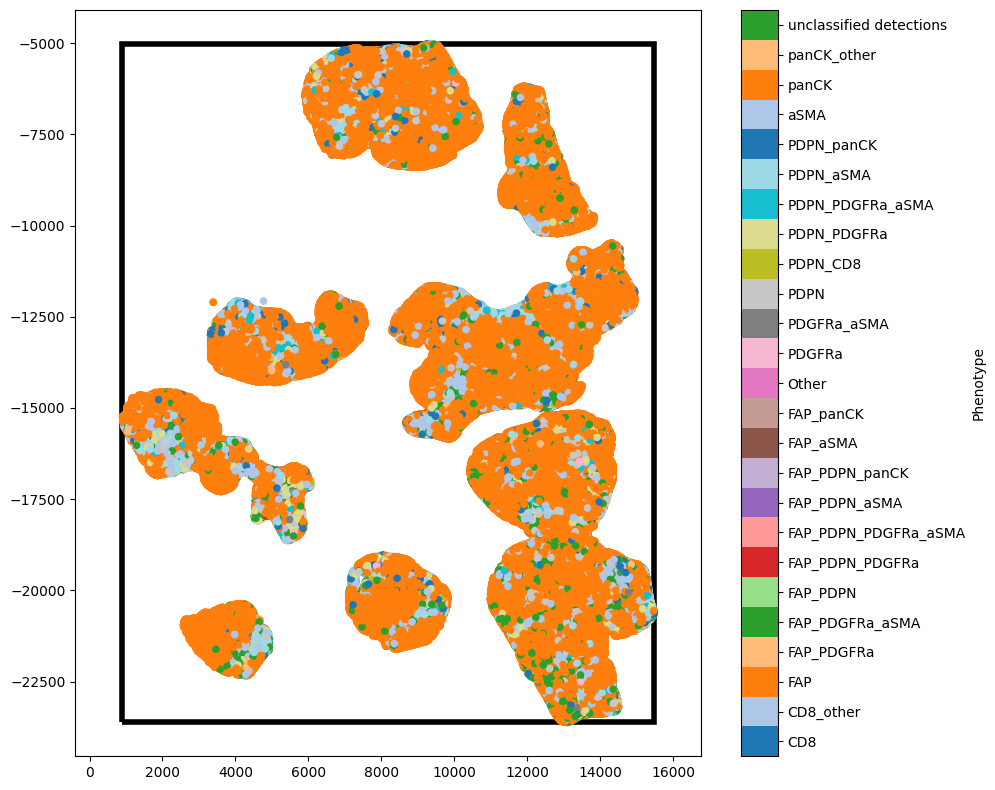

In [5]:
ms.visualise.visualise(domain,
                       color_by='Phenotype',
                       objects_to_plot=('collection', 'Cell centres'),
                       show_boundary=True)

In [8]:
domain.estimate_boundary(method = 'alpha shape', alpha_shape_kwargs=dict(alpha=10000))

if 'Alpha boundary' in domain.collections:
    qBoundary = ms.query(domain, ('collection,'), 'is', 'Alpha boundary')
    domain.delete_objects(qBoundary)

(<Figure size 1000x800 with 2 Axes>, <Axes: >)

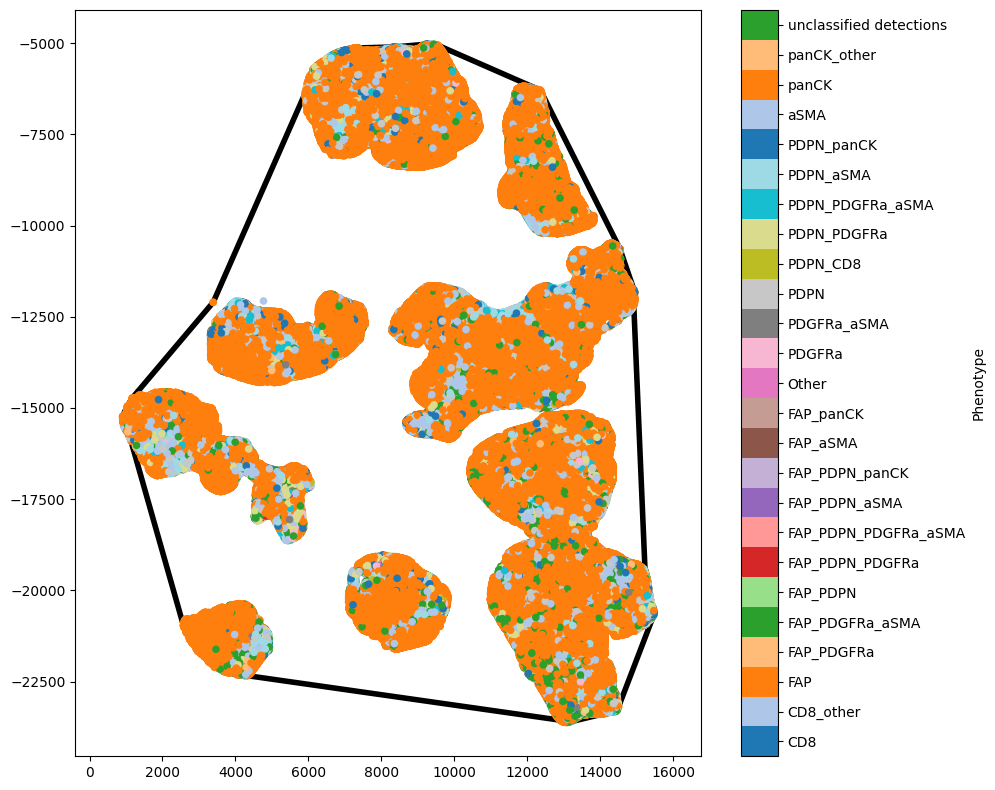

In [9]:
ms.visualise.visualise(domain,
                       color_by='Phenotype',
                       objects_to_plot=('collection', 'Cell centres'),
                       show_boundary=True)

In [10]:
qPoints = ms.query.query(domain, ('Collection',), 'is', 'Cell centres')

In [11]:
newIDs = domain.convert_objects(
    population = qPoints,
    collection_name = 'Alpha boundary',
    return_IDs = True,
    object_type = 'shape',
    conversion_method = 'alpha shape',
    conversion_method_kwargs = dict(alpha = 25, internal_boundaries = False)
)

In [12]:
qBoundary = ms.query.query(domain, ('collection',), 'is', 'Alpha boundary')

In [13]:
domain.simplify_shape_boundaries(
    qBoundary,
    delete_original_boundary = True,
    algorithm = 'Visvalingam-Whyatt',
    epsilon = 1500
)

KeyboardInterrupt: 

In [14]:
domain.estimate_boundary(method='alpha shape', alpha_shape_kwargs=dict(alpha=10000))
qBoundary = ms.query.query(domain, ('collection',), 'is', 'Alpha boundary')
qPoints = ms.query.query(domain, ('Collection',), 'is', 'Cell centres')

KeyboardInterrupt: 

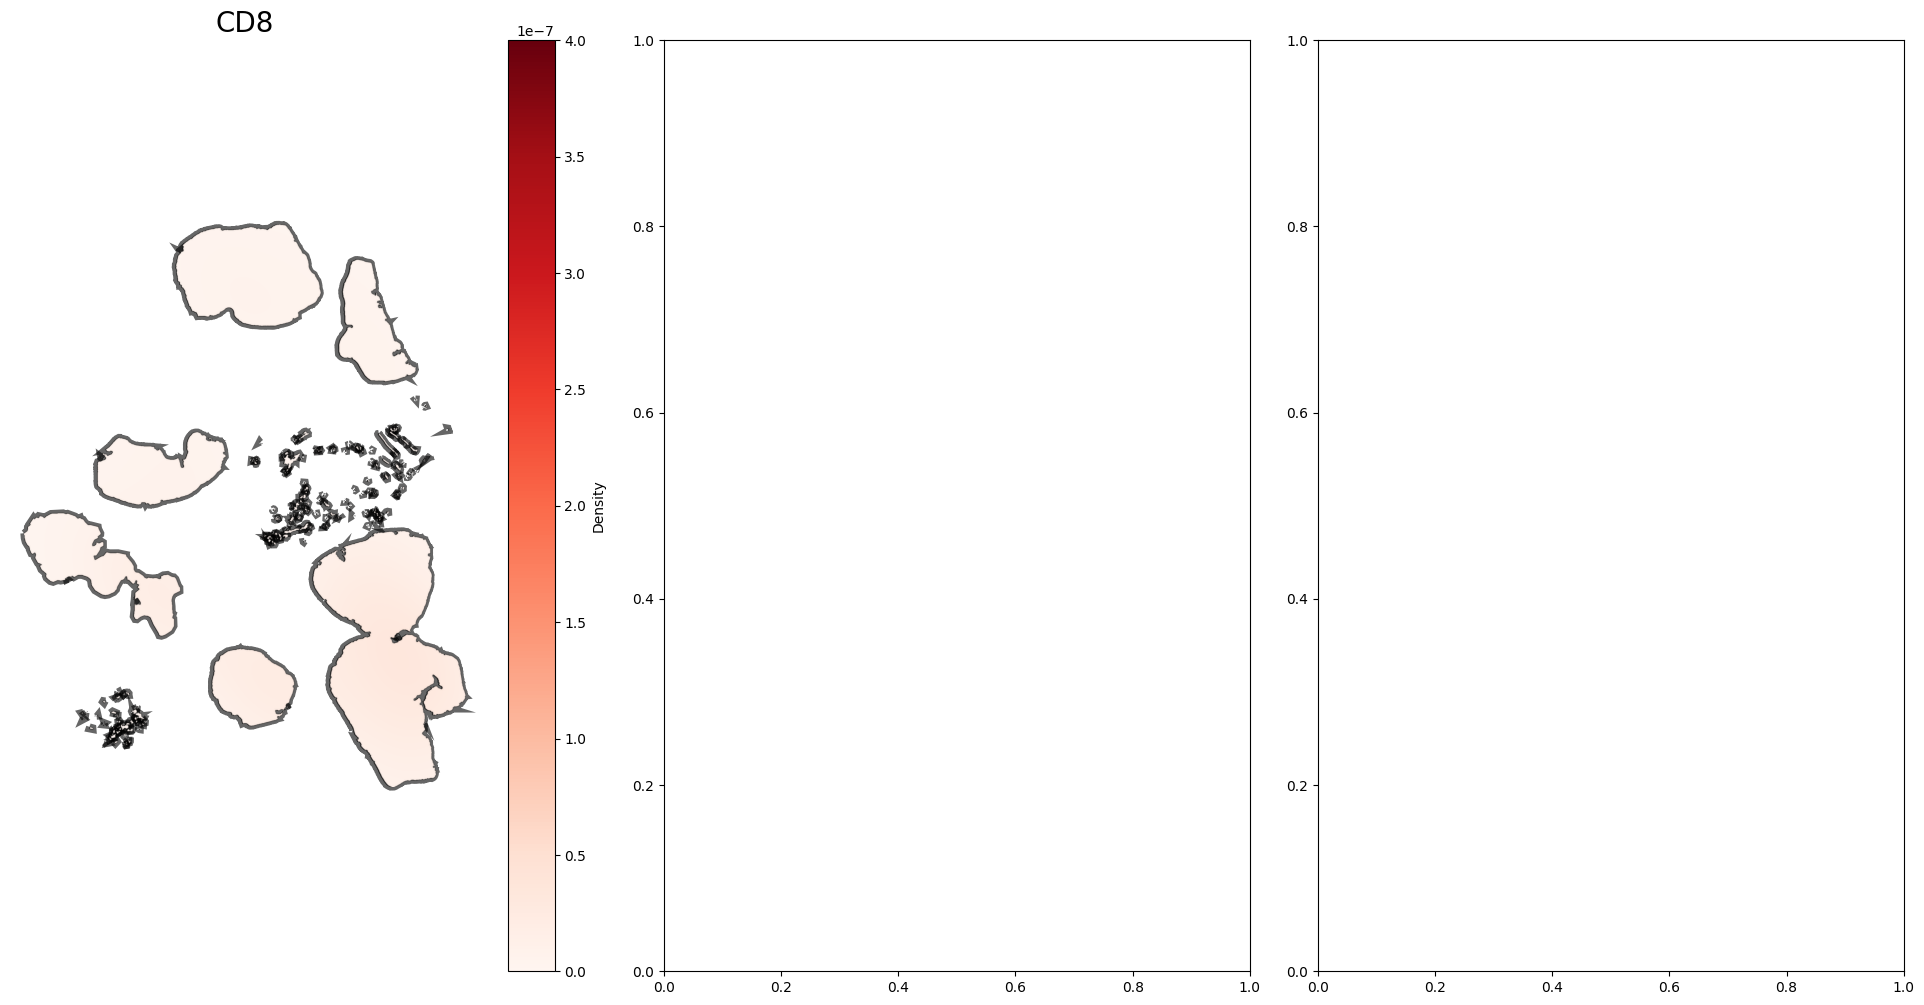

In [15]:
clusters_of_interest= ['CD8', 'PDPN', 'FAP']
fig, ax = plt.subplots(1,3, figsize=(20,10))
kde_maps = []

for i, id in enumerate(clusters_of_interest):
    qCluster2 = ms.query.query(domain, ('label', 'Phenotype'), 'is', id)

    kernel_density_matrix = ms.distribution.kernel_density_estimation(
        domain,
        population = qCluster2,
        include_boundaries=qBoundary,
        mesh_step=10,
        bw_method=0.05,
        visualise_output=False
    )

    kde_maps.append(kernel_density_matrix)

    ms.visualise.visualise_heatmap(
        domain,
        kernel_density_matrix,
        ax = ax[i],
        colorbar_limit=[0, 4e-7],
        heatmap_zorder=15,
        visualise_kwargs=dict(show_boundary = True)
    )

    ms.visualise.visualise(
        domain,
        ax = ax[i],
        add_cbar = False,
        objects_to_plot=qBoundary,
        show_boundary=False,
        shape_kwargs=dict(facecolor = [0,0,0,1], edgecolor = [0,0,0,1], linewidth = 5)
    )

    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].axis('off')
    ax[i].set_aspect('equal')
    ax[i].set_title(id, fontsize=20)

In [20]:
Wass_dist = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))
KL_dist = np.zeros((len(clusters_of_interest), len(clusters_of_interest)))

for i, clusterA in enumerate(clusters_of_interest):
    for j, clusterB in enumerate(clusters_of_interest):
        if j <= i:
            continue

        qPopA = ms.query.query(domain, ('label', 'Phenotype'), 'is', clusterA)
        qPopB = ms.query.query(domain, ('label', 'Phenotype'), 'is', clusterB)

        Wass_dist[i,j] = ms.distribution.sliced_wasserstein_distance(
            domain, qPopA, qPopB, POT_args={'n_projections':500, 'seed':42}
        )

        KL_dist[i,j] = ms.distribution.kl_divergence(kde_maps[i], kde_maps[j])

Text(61.222222222222214, 0.5, 'Cell type')

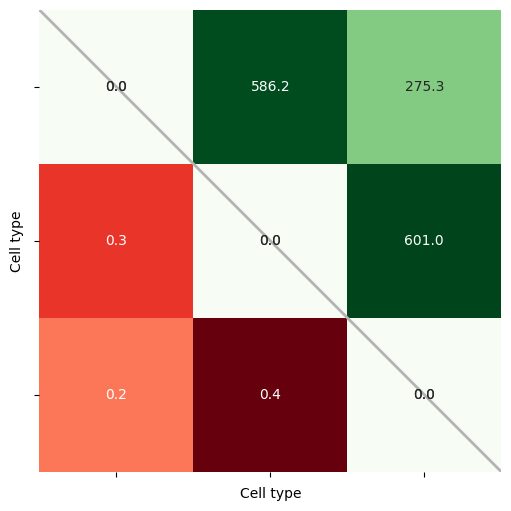

In [18]:
numeric_label_categories = [lab[8:] for lab in clusters_of_interest]

fig, ax = plt.subplots(figsize= (6,6))
fig.set_facecolor('none')
fig.patch.set_alpha(0)

SES_mask = np.triu(Wass_dist, k=0)
KL_mask = np.triu(KL_dist, k=0)

ax.plot([0, len(numeric_label_categories)], [0, len(numeric_label_categories)], 
        linestyle='-', color =[0.7, 0.7, 0.7], linewidth= 2)

sns.heatmap(
    KL_dist.T,
    xticklabels = numeric_label_categories,
    yticklabels= numeric_label_categories,
    ax= ax,
    cmap = 'Reds',
    square = True,
    linewidths = 0,
    linecolor='black',
    cbar_kws = dict(use_gridspec = False, location = 'top', label = 'KL divergence', pad = 0),
    mask = KL_mask,
    annot = True,
    fmt = ".1f",
    cbar = False
)

sns.heatmap(
    Wass_dist,
    xticklabels = numeric_label_categories,
    yticklabels= numeric_label_categories,
    ax= ax,
    cmap = 'Greens',
    square = True,
    linewidths = 0,
    linecolor='black',
    cbar_kws = dict(use_gridspec = False, location = 'top', label = 'Wasserstein distances', pad = 0),
    mask = SES_mask.T,
    annot = True,
    fmt = ".1f",
    cbar = False
)

ax.set_xlabel('Cell type')
ax.set_ylabel('Cell type')

where a low KL divergence suggests cells occupy the same region
a high KL divergence suggests the cell occupy different regions

for wasserstein score a high score suggest colocalisation
low score suggests they occupy different regions